# Cómo se rompe una partícula simulada y qué la reemplaza, paso a paso en el chancador de laboratorio, y dónde deja de funcionar el método

**Pregunta:** ¿Cómo decide la simulación que una partícula se rompe y qué la reemplaza, y dónde deja de funcionar el método en el chancador de mandíbulas de laboratorio de Barrios et al. (2020)?

- **Nivel:** 2, el método en la práctica
- **Requisitos previos:** el notebook 01 de este tema
- **Tiempo de lectura:** unos 90 minutos (las corridas en vivo suman unos cuatro minutos)

## Objetivos

Al terminar este notebook puedes:

- seguir una esfera desde la fuerza de contacto que siente, pasando por la energía que recibe, el daño que acumula, el t10 de su fractura y los tamaños de su progenie, hasta su reemplazo en el lecho, llamando a la función propia del paquete en cada paso y comprobando los dos primeros con un cálculo a mano;
- decir qué conserva el reemplazo y qué lo acota, y por qué la corrida se detiene por un límite del traslape de las esferas;
- leer la ventana estacionaria de un lote y el error estándar de su potencia media, y decir por qué una ventana de tres golpes no da error de su tendencia;
- decir qué pasa con el mayor traslape al crecer el lote y en cada peldaño de la escalera de traslape del producto, con las corridas versionadas de las tres alimentaciones junto a las corridas en vivo, y decir dónde deja de funcionar el método en este chancador;
- preparar la máquina, la roca y la alimentación de tu propio chancador y saber qué leer en la salida.

## Preparación

Este notebook llama al paquete publicado `crushdem` 0.6.0 en cada paso, en el mismo entorno que el notebook 01. Se instala con sus núcleos compilados y la pila numérica fijada:

```bash
pip install "crushdem[jit]==0.6.0" numba==0.68.1 llvmlite==0.50.0 numpy==2.4.6 matplotlib==3.11.2
```

La celda imprime las versiones e importa las funciones de contacto y de fractura que usan los pasos, el caso del chancador de laboratorio, el protocolo de comparación y los puntos de operación del producto.

In [1]:
# Imprime las versiones de las herramientas de este notebook, para compararlas con notebooks/requirements.txt
import contextlib
import importlib.metadata as md
import io
import json
import math
import sys
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt

for name in ('crushdem', 'numba', 'llvmlite', 'numpy', 'matplotlib'):
    print(name, md.version(name))

# El notebook está tres carpetas bajo la raíz del repositorio; el pipeline se importa por su ruta
ROOT = Path("../../..").resolve()
sys.path.insert(0, str(ROOT / "data-pipeline"))
# Solo funciones públicas: el notebook no define ningún método propio
from crushdem import ContactTable, OverlapError, ParticleState, PairParams, Simulation, comparison, stable_time_step
from crushdem.breakage import BreakageBounds, breakage_probability, damage_increment, draw_progeny
from crushdem.breakage import BETA_PARAMS, incomplete_beta, median_fracture_energy, progeny_curve, t10_of_energy
from crushdem.cases import barrios2020 as case
from crushdem.core.materials import effective_modulus, energy_share, tsuji_alpha
from crushdem.core.state import rayleigh_time_step
from crushdem.machines import barrios_contact_table
from pipeline.dem import points as P
plt.rcParams.update({"figure.figsize": (8.6, 3.8), "axes.grid": True, "grid.alpha": 0.3, "font.size": 9})

crushdem 0.6.0
numba 0.68.1
llvmlite 0.50.0
numpy 2.4.6
matplotlib 3.11.2


## Datos

Dos fuentes. La roca y sus ensayos de una partícula son los del paquete: las 30 fuerzas de ruptura por clase de tamaño de la Fig. 6b de Barrios et al. (2020), https://doi.org/10.3390/min10080717, CC BY 4,0, digitalizadas y entregadas como datos del paquete; `case.paper_ore` deriva la roca de ellas. La segunda fuente es el documento versionado del cálculo del producto, `data/derived/dem/jaw-lab.json` (fila `dem-run` del catálogo), escrito por `data-pipeline/run.py dem`, que corre este mismo caso a tamaño completo (6 kg) para las tres alimentaciones y guarda cada intento. El notebook lo lee solo por el control de corrida y por los intentos y series por golpe de la comparación de la sección 4; todo número en vivo se calcula aquí.

La celda lee el documento e imprime su estado y el control de corrida que registra.

In [2]:
# El documento versionado de las corridas de tamaño completo, leído aquí solo por el control de corrida y los
# intentos de la sección 4
doc = json.loads((ROOT / "data/derived/dem/jaw-lab.json").read_text(encoding="utf-8"))
settings = doc["settings"]
final = {pt["feed_class"]: pt["simulation"] for pt in doc["points"]}
print("estado del documento:", doc["state"], "|", "crushdem", doc["package"]["version"], doc["package"]["backend"])
print("escalera de traslape:", settings["overlap_ladder"], "| detención tras", settings["stall_strokes"],
      "golpes | semilla", doc["seed"], "| lote", settings["batch_kg"], "kg")

estado del documento: partial | crushdem 0.6.0 numba
escalera de traslape: [0.3, 0.5] | detención tras 40 golpes | semilla 1 | lote 6.0 kg


## Método

Un lote es un ciclo de golpes, y cada golpe es un ciclo de pasos; la regla de reemplazo sigue a Cleary y Sinnott (2015) y a Barrios et al. (2020), con la resistencia de una esfera de Tavares (2022). En cada paso el motor encuentra los contactos, evalúa las fuerzas de la ley de contacto, mueve las esferas y la placa, y suma el trabajo que hacen los contactos de cada esfera mientras la cargan. Cada 50 pasos el anfitrión toma ese trabajo, termina los eventos que cesaron, decide qué esferas se rompen y las reemplaza. Los ocho pasos siguientes desarman ese ciclo en el orden de sus causas: el contacto, la resistencia de una esfera, el daño, el t10, la progenie, el reemplazo, el ciclo de golpes y la ventana que convierte golpes en los promedios que se comparan con una medición.

### Paso 1: el contacto y el paso de tiempo

Dos esferas de roca de radios $R_i$ y $R_j$ se hunden una en la otra el traslape $\delta$ y se empujan con la fuerza de Hertz

$$F_n = \tfrac{4}{3}\,E^{*}\sqrt{R^{*}}\;\delta^{3/2}, \qquad E^{*} = \left(\frac{1-\nu_i^2}{E_i} + \frac{1-\nu_j^2}{E_j}\right)^{-1}, \qquad R^{*} = \frac{R_iR_j}{R_i+R_j},$$

con los módulos de Young $E$ y las razones de Poisson $\nu$ de los dos cuerpos. El paso de la integración no puede superar una fracción $f$ del tiempo de Rayleigh, el tiempo que tarda una onda de tensión en cruzar la esfera más pequeña (como lo enuncia la documentación de fix check/timestep/gran),

$$\Delta t = f\,\Delta t_R, \qquad \Delta t_R = \frac{\pi R\sqrt{\rho/G}}{0.1631\,\nu + 0.8766},$$

con $R$, $\rho$, $G$ y $\nu$ el radio, la densidad, el módulo de corte y la razón de Poisson de esa esfera, y $f = 0.1$ en este producto. La celda calcula $E^{*}$ de dos esferas de roca a mano y con el paquete, la fuerza con tres traslapes, la constante de amortiguamiento de la restitución roca-roca y el paso de tiempo que usa la corrida.

In [3]:
# Paso 1: el contacto de dos esferas de roca de 10 mm, a mano y con el paquete, y el paso de tiempo estable de la
# corrida
ore_mat = case.ORE_MATERIAL
e_star = effective_modulus(ore_mat, ore_mat)
by_hand = 1.0 / (2.0 * (1.0 - ore_mat.poisson**2) / ore_mat.youngs_modulus)
r_star = 0.005 * 0.005 / (0.005 + 0.005)
print(f"E* paquete {e_star:.4g} Pa, a mano {by_hand:.4g} Pa, R* = {r_star * 1e3:.2f} mm")
for overlap_um in (5.0, 20.0, 80.0):
    delta = overlap_um * 1e-6
    print(f"traslape {overlap_um:5.1f} um: F_n = {4.0 / 3.0 * e_star * math.sqrt(r_star) * delta ** 1.5:8.2f} N")
print(f"constante de amortiguamiento con restitución 0,35: alpha = {tsuji_alpha(0.35):.4f}")
table = barrios_contact_table()
probe = ParticleState.from_arrays([[0, 0, 0]], [0.5 * P.MINIMUM_SPHERE_MM * 1e-3], table, material=[0])
dt = stable_time_step(probe, table, 0.1)
dt_rayleigh = rayleigh_time_step(0.5 * P.MINIMUM_SPHERE_MM * 1e-3, ore_mat)
print(f"paso de tiempo de la corrida {dt:.3e} s = {dt / dt_rayleigh:.2f} del tiempo de Rayleigh {dt_rayleigh:.3e} s")

E* paquete 1.333e+08 Pa, a mano 1.333e+08 Pa, R* = 2.50 mm
traslape   5.0 um: F_n =     0.10 N
traslape  20.0 um: F_n =     0.80 N
traslape  80.0 um: F_n =     6.36 N
constante de amortiguamiento con restitución 0,35: alpha = 0.7096
paso de tiempo de la corrida 3.559e-06 s = 0.10 del tiempo de Rayleigh 3.559e-05 s


El módulo efectivo de dos esferas de roca es 1,333e+08 Pa a mano y con el paquete, con un radio efectivo de 2,50 mm para dos esferas de 10 mm. La fuerza crece como el traslape elevado a 3/2: 0,10 N con 5 micrómetros, 0,80 N con 20 y 6,36 N con 80, así que cuadruplicar el traslape multiplica la fuerza por 8. La constante de amortiguamiento de Tsuji et al. (1992) para una restitución de 0,35 es 0,7096. El paso de tiempo de 3,559e-06 s es un décimo del tiempo de Rayleigh de la esfera de 4 mm, 3,559e-05 s, porque la esfera mínima que conserva el producto fija el contacto más rígido y rápido, y toda otra esfera queda entonces bien dentro del límite.

El artículo no da ningún parámetro de fractura de su roca, solo la fuerza de ruptura de 30 partículas en cada una de tres clases de tamaño (Fig. 6b, página 7). El paquete convierte la fuerza mediana $F_{50}$ de cada clase en la energía específica que absorbe una esfera de ese tamaño cuando dos placas de acero la aprietan hasta esa fuerza, con el contacto de Hertz de los dos materiales,

$$\delta = \left(\frac{3F}{4E^{*}\sqrt{R}}\right)^{2/3}, \qquad E_{50} = \frac{2\,e\cdot\tfrac{2}{5}F_{50}\,\delta}{m}, \qquad E_{50}(d) = E_\infty\left[1 + \left(\frac{d_0}{d}\right)^{\phi}\right],$$

con $R$ el radio de la esfera, $E^{*}$ el módulo efectivo de roca contra acero, $e$ la fracción del trabajo de contacto que entra a la roca (Tavares, 2022, ecuación 9), $m$ la masa de la esfera y el factor 2 por los dos contactos. El efecto de tamaño se ajusta luego con las dos clases gruesas con el exponente $\phi$ fijo en el valor del gneis de Tavares (2022), y la varianza $\sigma^2$ de la ley lognormal del notebook anterior se toma de la dispersión de las 30 fuerzas, con tope en 1,2. La celda imprime las tres clases, el ajuste y el valor de la varianza según los datos.

In [4]:
# Paso 2: la roca que deriva el paquete de los ensayos de una partícula del artículo, y su efecto de tamaño
ore, derivation = case.paper_ore("A", seed=1)
print("clase          fuerza mediana [N]   sigma de ln F   E50 mapeada [J/kg]")
for name, stats in derivation["classes"].items():
    e50_class = derivation["e50_j_kg"][name]
    print(f"{name:>10s} {stats['empirical_median_force_n']:18.1f} {stats['sigma_ln_force']:15.3f} {e50_class:19.1f}")
print(f"E_inf = {ore.e_inf:.2f} J/kg, d0 = {ore.d0 * 1e3:.2f} mm, phi = {ore.phi} (fijo),",
      f"sigma^2 = {ore.variance} (valor de los datos {derivation['variance_from_data']:.2f})")
print(f"desajuste de la clase más fina en ln E50: {derivation['fit_residual_ln'][2]:.2f}")

clase          fuerza mediana [N]   sigma de ln F   E50 mapeada [J/kg]
     63/53             4831.1           1.029                26.6
 31.5/26.5             1965.6           1.053                58.2
 16.0/13.2             1701.9           1.075               451.1
E_inf = 13.84 J/kg, d0 = 55.02 mm, phi = 1.82 (fijo), sigma^2 = 1.2 (valor de los datos 3.08)
desajuste de la clase más fina en ln E50: -0.98


Las fuerzas medianas son 4831,1, 1965,6 y 1701,9 N para las tres clases y se mapean a 26,6, 58,2 y 451,1 J/kg: la clase más fina, cuya fuerza apenas baja de la intermedia, es con mucho la más resistente por unidad de masa porque la energía va como la fuerza a la 5/3 y la masa como el tamaño al cubo. El ajuste con las dos clases gruesas da $E_\infty$ = 13,84 J/kg y $d_0$ = 55,02 mm, y yerra la clase más fina en -0,98 en el logaritmo, un factor de 2,7: el ajuste pone la mediana en 168,6 J/kg para una esfera de 14,6 mm donde los datos mapean 451.1. La varianza según la dispersión de las fuerzas es 3,08, sobre el 1,2 que permite el rango de la literatura que el producto toma como tope. Dos supuestos de la derivación cargan entonces la alimentación más fina, el exponente fijo y la extrapolación bajo 29 mm, y el registro del paquete lo dice.

La figura 1 dibuja el efecto de tamaño con las tres clases mapeadas, y la probabilidad de fractura frente a la energía del evento para esferas de 57,5, 29,0 y 14,6 mm.

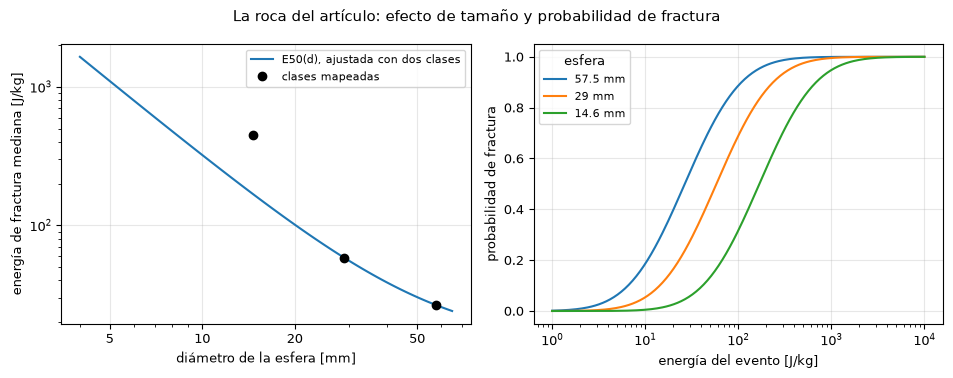

In [5]:
# Figura 1: el efecto de tamaño E50(d) con las tres clases mapeadas, y la probabilidad de fractura de tres tamaños
d_grid = np.logspace(math.log10(0.004), math.log10(0.065), 80)
fig, axes = plt.subplots(1, 2, figsize=(9.6, 3.8))
axes[0].loglog(d_grid * 1e3, median_fracture_energy(d_grid, ore), "-", label="E50(d), ajustada con dos clases")
mean_d = [case.SIZE_CLASS_MEAN_M[k] * 1e3 for k in derivation["classes"]]
axes[0].loglog(mean_d, [derivation["e50_j_kg"][k] for k in derivation["classes"]], "ko", label="clases mapeadas")
axes[0].set_xlabel("diámetro de la esfera [mm]")
axes[0].set_xticks([5, 10, 20, 50])
axes[0].xaxis.set_major_formatter(plt.ScalarFormatter())
axes[0].xaxis.set_minor_formatter(plt.NullFormatter())
axes[0].set_ylabel("energía de fractura mediana [J/kg]")
axes[0].legend(fontsize=8)
energy = np.logspace(0, 4, 200)
for d_mm in (57.5, 29.0, 14.6):
    axes[1].semilogx(energy, breakage_probability(energy, d_mm * 1e-3, ore), label=f"{d_mm:g} mm")
axes[1].set_xlabel("energía del evento [J/kg]")
axes[1].set_ylabel("probabilidad de fractura")
axes[1].legend(title="esfera", fontsize=8)
fig.suptitle("La roca del artículo: efecto de tamaño y probabilidad de fractura")
fig.tight_layout()
plt.show()

Lectura de la figura 1. A la izquierda el efecto de tamaño sube hacia los tamaños pequeños, pasa por las dos clases gruesas por construcción y queda bajo la más fina, que es el desajuste de arriba. A la derecha la probabilidad de fractura es una curva en S ancha en un eje logarítmico: con una varianza de 1,2 la energía que rompe una esfera con probabilidad 0,1 y la que la rompe con probabilidad 0,9 difieren en más de un orden de magnitud, y la curva de la esfera de 14,6 mm queda más de seis veces a la derecha de la de 57,5 mm. La figura no muestra el efecto del daño, que mueve a una esfera sobre su propia curva, ni ninguna medición de la roca del artículo más allá de las tres medianas.

Un evento cuya energía $e\,E_k$ queda bajo la energía de fractura $E$ no rompe la esfera pero la debilita. Tavares (2022, ecuaciones 11 y 12) escribe la energía de fractura tras el evento como $E' = E\,(1 - D)$, con el daño $D$ la menor raíz de

$$D = \left[\frac{2\gamma}{2\gamma - 5D + 5}\;\frac{e\,E_k}{E}\right]^{2\gamma/5},$$

donde $\gamma$ es el coeficiente de daño (3,5 aquí, un supuesto del producto tomado de la mitad del rango que da el artículo) y $e\,E_k/E$ la energía del evento como parte de la energía de fractura. `damage_increment` lo resuelve por acotación. La celda imprime el daño de eventos únicos al 10, 30, 50 y 80 por ciento de la energía de fractura, y luego golpea una esfera de 14,6 mm una y otra vez con eventos del 30 por ciento de su energía de fractura original, aplicando $E' = E(1-D)$ tras cada uno, hasta que la energía del evento alcanza lo que queda.

In [6]:
# Paso 3: el daño de un evento bajo la energía de fractura, y una esfera golpeada una y otra vez por eventos de 30
# por ciento de ella
ratios = np.linspace(0.01, 0.99, 99)
damage = damage_increment(ratios * 100.0, 100.0, ore.gamma)
d_at = {r: float(damage_increment(r * 100.0, 100.0, ore.gamma)) for r in (0.1, 0.3, 0.5, 0.8)}
print("daño D de un evento al 10, 30, 50 y 80 por ciento de la energía de fractura:",
      {k: round(v, 4) for k, v in d_at.items()})
e_frac = float(median_fracture_energy(0.0146, ore))
event, current, history = 0.3 * e_frac, e_frac, []
while event < current and len(history) < 30:
    increment = float(damage_increment(event, current, ore.gamma))
    current *= 1.0 - increment
    history.append((increment, current))
print(f"esfera de 14,6 mm, energía de fractura {e_frac:.1f} J/kg, eventos de {event:.1f} J/kg")
print(f"la esfera se rompe en el evento {len(history) + 1};",
      "su energía de fractura antes de cada evento [J/kg]:",
      [round(e_frac, 1)] + [round(c, 1) for _, c in history])

daño D de un evento al 10, 30, 50 y 80 por ciento de la energía de fractura: {0.1: 0.0189, 0.3: 0.0921, 0.5: 0.2014, 0.8: 0.4652}
esfera de 14,6 mm, energía de fractura 168.6 J/kg, eventos de 50.6 J/kg
la esfera se rompe en el evento 8; su energía de fractura antes de cada evento [J/kg]: [168.6, 153.1, 136.8, 119.6, 101.1, 80.7, 57.0, 23.3]


El daño crece más rápido que el evento: 0,0189 al 10 por ciento, 0,0921 al 30, 0,2014 al 50 y 0,4652 al 80 por ciento de la energía de fractura. La esfera de 14,6 mm, con una energía de fractura de 168,6 J/kg, golpeada con eventos de 50,6 J/kg, un tercio de lo que necesita, pierde energía de fractura en cada evento, 168,6, 153,1, 136,8, 119,6, 101,1, 80,7, 57,0 y 23,3 J/kg, y se rompe en el octavo evento, cuando los 50,6 J/kg del evento superan los 23,3 J/kg que quedan. Este es el mecanismo por el que un lecho de esferas que ninguno de sus contactos puede romper de una vez igual chanca: las esferas alojadas en el lecho se cargan muchas veces, y cada carga les quita algo de resistencia.

Cuando una esfera se rompe, el tamaño de sus piezas sale de un solo número, el porcentaje $t_{10}$ de su masa que termina bajo la décima parte de su tamaño. Tavares (2022, ecuación 20) lo da como una función saturante de la energía que recibió la esfera:

$$t_{10} = A\left[1 - \exp\!\left(-\,b'\,\frac{e\,E_k}{E_{50}(d)}\right)\right],$$

con $A$ el mayor $t_{10}$ de un solo evento (59,7 por ciento), $b'$ una constante adimensional (0,025), $e\,E_k$ la energía específica del evento y $E_{50}(d)$ la energía de fractura mediana del tamaño de la esfera, usada aquí como mediana de las partículas que se rompieron (un supuesto declarado en la documentación del paquete). La celda la evalúa para una esfera gruesa y una fina con tres energías absolutas, con el paquete y a mano.

In [7]:
# Paso 4: t10 desde la energía del evento, a mano y con el paquete, para dos esferas con tres energías
print("esfera [mm]  E50 [J/kg]  e Ek [J/kg]  t10 paquete [%]  t10 a mano [%]")
for d_mm in (57.5, 14.6):
    e50 = float(median_fracture_energy(d_mm * 1e-3, ore))
    for event_energy in (25.0, 100.0, 400.0):
        t10_pkg = float(t10_of_energy(event_energy, d_mm * 1e-3, ore))
        t10_hand = ore.a_max * (1.0 - math.exp(-ore.b_prime * event_energy / e50))
        print(f"{d_mm:11.1f} {e50:11.1f} {event_energy:12.0f} {t10_pkg:15.3f} {t10_hand:15.3f}")

esfera [mm]  E50 [J/kg]  e Ek [J/kg]  t10 paquete [%]  t10 a mano [%]
       57.5        26.6           25           1.386           1.386
       57.5        26.6          100           5.354           5.354
       57.5        26.6          400          18.703          18.703
       14.6       168.6           25           0.221           0.221
       14.6       168.6          100           0.879           0.879
       14.6       168.6          400           3.438           3.438


El paquete y el cálculo a mano coinciden en tres decimales. Con la misma energía la esfera gruesa se rompe mucho más fino que la fina: 100 J/kg dan un $t_{10}$ de 5,354 por ciento para la esfera de 57,5 mm, cuya energía de fractura mediana es 26,6 J/kg, y 0,879 por ciento para la de 14,6 mm, cuya mediana es 168,6 J/kg, porque lo que cuenta es la energía como múltiplo de la mediana propia del tamaño. Las esferas fuertes y finas de la alimentación 16/13,2 mm se rompen entonces en pocas piezas grandes, y las esferas débiles y gruesas de la alimentación 63/52 mm en muchas.

Desde $t_{10}$ el paquete construye toda la distribución de tamaños acumulada de las piezas. La masa que pasa una fracción $1/n$ del tamaño del padre, $t_n$, es una función beta incompleta regularizada (Tavares, 2022, ecuación 16):

$$t_n = 100\; I_{t_{10}/100}\!\left(\alpha_n,\,\beta_n\right), \qquad I_x(a,b) = \frac{\int_0^x s^{a-1}(1-s)^{b-1}\,ds}{B(a,b)},$$

con $(\alpha_n, \beta_n)$ los parámetros tabulados para $n$ = 1,2, 1,5, 2, 4, 25, 50 y 75 (Tabla 2 del artículo), $B$ la función beta y $s$ la variable de integración. El paso 5a comprueba la evaluación por fracción continua del paquete frente a una integral independiente de Gauss-Legendre de la densidad, tras la sustitución $u = s^{a}$ que quita la singularidad en 0. El paso 5b sortea 400 padres de 60 mm con $t_{10}$ = 15 por ciento con `draw_progeny`, que convierte la distribución de masa en esferas: sortea piezas de la distribución en número que lleva la distribución de masa, conserva las mayores que caben en la masa del padre, y manda la masa bajo la esfera mínima de 4 mm a los finos.

In [8]:
# Paso 5a: la ecuación 16, t_n = 100 I_x(alpha_n, beta_n), frente a una integral independiente de Gauss-Legendre
# de la densidad beta
t10_value = 15.0
x = t10_value / 100.0
nodes, weights = np.polynomial.legendre.leggauss(64)
print("n    alpha_n  beta_n   paquete [%]   integral independiente [%]")
for n in (2.0, 4.0, 25.0):
    a, b = BETA_PARAMS[n]
    # la sustitución u = t^a quita la singularidad de la densidad en 0
    top = x**a
    u = 0.5 * top * (nodes + 1.0)
    integrand = (1.0 - u ** (1.0 / a)) ** (b - 1.0)
    integral = 0.5 * top * np.sum(weights * integrand) / a / (math.gamma(a) * math.gamma(b) / math.gamma(a + b))
    print(f"{n:4.0f} {a:9.3f} {b:7.3f} {100 * incomplete_beta(a, b, x):12.3f} {100 * integral:22.3f}")

n    alpha_n  beta_n   paquete [%]   integral independiente [%]
   2     0.959   5.780       62.616                 62.616
   4     1.105   2.619       30.377                 30.377
  25     0.981   0.524        8.519                  8.519


El paquete y la integral independiente coinciden en tres decimales en los tres tamaños: 62,616, 30,377 y 8,519 por ciento para $n$ = 2, 4 y 25 con un $t_{10}$ de 15 por ciento. La celda siguiente compara la ley con lo que entregan 400 padres sorteados.

In [9]:
# Paso 5b: 400 padres de 60 mm sorteados con t10 = 15 por ciento, frente a la curva de la ecuación 16
curve = progeny_curve(t10_value)
rng = np.random.default_rng(1)
d_parent = 0.06
mass = 2700.0 * math.pi / 6.0 * d_parent**3
drawn = [draw_progeny(mass, d_parent, 2700.0, t10_value, ore.min_diameter, rng) for _ in range(400)]
print("razón de tamaño n   curva [%]   media de 400 padres [%]")
for n in (1.2, 2.0, 4.0):
    below = []
    for p in drawn:
        pieces = 2700.0 * math.pi / 6.0 * np.array(p.diameters) ** 3
        below.append(pieces[np.array(p.diameters) < d_parent / n].sum() + p.fines_kg)
    print(f"{n:15.1f} {curve.cumulative(1.0 / n):10.2f} {100 * np.mean(below) / mass:24.2f}")
fines = 100 * np.mean([p.fines_kg for p in drawn]) / mass
law_fines = curve.cumulative(ore.min_diameter / d_parent)
print(f"finos bajo el tamaño mínimo, curva {law_fines:.2f} %, sorteados {fines:.2f} %")
print(f"piezas por padre {np.mean([len(p.diameters) for p in drawn]):.1f}")

razón de tamaño n   curva [%]   media de 400 padres [%]
            1.2      94.17                    94.73
            2.0      62.62                    60.39
            4.0      30.38                    26.81
finos bajo el tamaño mínimo, curva 11.68 %, sorteados 11.68 %
piezas por padre 73.5


Los finos de los padres sorteados igualan los de la ley, 11,68 por ciento, porque el paquete los fija por construcción. En los tamaños mayores la muestra queda bajo la ley: 60,39 frente a 62,62 por ciento a la mitad del tamaño del padre y 26,81 frente a 30,38 por ciento a un cuarto, una brecha de hasta 3,6 puntos. Un padre tiene una masa finita, unas 73,5 piezas aquí, y una pieza mayor que la masa restante no puede sortearse, así que las piezas más grandes quedan subrepresentadas; las pruebas del propio paquete acotan esta desviación en 4 puntos. Nada en la curva muestrada dice que la ley esté equivocada: dice lo que puede seguir un padre finito.

El padre se retira y sus piezas se escriben en casillas libres del grupo de partículas con la velocidad y el giro del padre. Dos hechos de conservación y una cota hacen seguro el reemplazo. Masa: las piezas y los finos llevan la masa del padre, $\sum_k m_k + m_{\text{fines}} = m_{\text{parent}}$, con una cota de residuo relativo de $10^{-9}$. Momentum: las piezas conservan la velocidad del padre, así que el momentum se conserva y la energía cinética solo puede bajar. La cota: las piezas de un padre pesado no caben todas en el volumen del padre, así que parten dentro de él y se separan con una relajación solo de posiciones hasta que todo traslape queda bajo $10^{-3}$ del radio menor, y la energía de Hertz que queda en esos traslapes, la energía que inyecta el reemplazo, no debe exceder una parte de la energía que absorbió el padre,

$$E_{\text{inj}} \le 0.1\; m\,e\,E_k, \qquad E_{\text{inj}} = \sum \tfrac{8}{15}E^{*}\sqrt{R^{*}}\,\delta^{5/2},$$

con $m\,e\,E_k$ la energía absorbida del padre y la suma sobre los traslapes que quedan. Un padre cuyas piezas no caben en las casillas libres (el tope de partículas) o no pueden colocarse dentro de la cota no se rompe en este servicio, y el evento espera. La celda construye el chancador de laboratorio, corre dos golpes de 0,5 kg de la alimentación 16/13,2 mm con el registro del gestor de fractura e imprime las cotas, los cinco primeros eventos y los totales.

In [10]:
# Paso 6: el reemplazo de un padre, en dos golpes en vivo: el registro de eventos del gestor y sus cotas
machine, sim = case.build(ore, 0.5, 6.0, 1, 800, 0.3, "numba", feed_class="16/13.2")
sim.run_cycles(2, machine.period_s)
events = sim.breakage.events()
report = sim.breakage_report()
print("cotas:", sim.bounds)
print("evento  padre [mm]  energía [J/kg]  t10 [%]  hijas  finos [g]  residuo de masa [kg]  inyectada/absorbida")
for k in range(5):
    ev = {name: values[k] for name, values in events.items()}
    print(f"{k + 1:5d} {ev['diameter_m'] * 1e3:12.2f} {ev['specific_energy_j_kg']:13.1f} {ev['t10_percent']:8.3f}",
          f"{ev['n_progeny']:8d} {ev['fines_kg'] * 1e3:10.3f} {ev['mass_residual_kg']:19.1e}",
          f"{ev['injected_energy_j'] / ev['absorbed_energy_j']:18.2e}")
print(f"{report['n_events']} eventos en dos golpes;",
      f"mayor parte inyectada de la energía absorbida {report['max_injected_fraction']:.2e};",
      f"mayor razón de residuo de masa {report['max_mass_residual_ratio']:.1e}")
print(f"diferidas por el tope de partículas {report['n_deferred_cap']},",
      f"diferidas por colocación {report['n_deferred_placement']}")

cotas: BreakageBounds(mass_tolerance=1e-09, max_injection_fraction=0.1, max_relax_overlap=0.001, max_relax_iterations=400, min_damage_energy_fraction=0.001)
evento  padre [mm]  energía [J/kg]  t10 [%]  hijas  finos [g]  residuo de masa [kg]  inyectada/absorbida
    1        15.87          76.0    0.768        2      0.074             2.7e-20           6.11e-08
    2        15.40          84.7    0.814        3      0.076             1.0e-18           1.47e-07
    3        14.59          43.8    0.386        3      0.032             9.7e-19           5.26e-07
    4        13.43         422.8    3.165        6      0.274            -1.6e-19           7.11e-10
    5        13.98         729.1    5.710        6      0.532             1.1e-18           1.29e-09
12 eventos en dos golpes; mayor parte inyectada de la energía absorbida 4.93e-03; mayor razón de residuo de masa 5.1e-16
diferidas por el tope de partículas 0, diferidas por colocación 1


Los primeros eventos son débiles: padres de 13,43 a 15,87 mm reciben de 43,8 a 729,1 J/kg, dan $t_{10}$ entre 0,386 y 5,710 por ciento y se rompen en 2 a 6 piezas, con la mayor parte de la masa en dos o tres esferas grandes y unos gramos de finos. La masa cierra con un residuo de cerca de $10^{-18}$ kg por evento, 5,1e-16 del padre en el peor caso frente a la cota de $10^{-9}$, y la energía inyectada por las colocaciones es a lo más 4,93e-03 de lo que absorbió el padre, frente a la cota de 0,1. Ninguno de los 12 eventos de los dos golpes fue diferido por el tope de partículas y uno fue diferido por colocación, así que las cotas actúan como se diseñaron. Una esfera gruesa no se pulveriza en su primera fractura: se parte y cada pieza se carga otra vez, que es por qué el lote necesita golpes.

La misma construcción de celda muestra la guarda que detiene una corrida. `case.build` recibe el límite de traslape como fracción del radio menor, y todo paso cuyo mayor traslape lo pase lanza `OverlapError`. La celda siguiente lo fija en 0,05, mucho más estricto que el 0,3 del modelo de contacto, para que el error aparezca dentro de un golpe.

In [11]:
# La guarda de traslape: los mismos golpes con un límite de 0,05 del radio menor se detienen con el error propio
# del paquete
machine, tight = case.build(ore, 0.5, 6.0, 1, 800, 0.05, "numba", feed_class="16/13.2")
try:
    tight.run_cycles(3, machine.period_s)
except OverlapError as error:
    print("OverlapError:", error)
print(f"tiempo simulado al detenerse {tight.time:.3f} s,",
      f"periodo del golpe {machine.period_s:.3f} s")

OverlapError: overlap of 0.051 of the smaller radius at sphere 17 exceeds the limit 0.050 (step 73400); the run is unstable or the time step too large
tiempo simulado al detenerse 0.261 s, periodo del golpe 0.167 s


El error nombra el traslape (0,051 del radio menor frente al límite de 0,050), la esfera y el paso, y la corrida se detiene 0,261 s dentro de la simulación, en su segundo golpe de 0,167 s. El mensaje dice "la corrida es inestable o el paso de tiempo demasiado grande", que es el único diagnóstico que puede hacer la comprobación: no distingue un lecho atascado de un evento local como una esfera pellizcada en un borde de la placa. El producto usa primero el valor por defecto del paquete de 0,3 y, si una corrida se detiene ahí, prueba 0,5 una vez; la sección 4 lee lo que hizo esa escalera a tamaño completo.

`run_attempt` corre un golpe a la vez y registra la masa retenida, la masa pasada, la potencia media de la placa oscilante y el mayor traslape. Se detiene por una de cuatro reglas, probadas tras cada golpe en este orden: el lote está completo cuando no queda esfera retenida y la alimentación pendiente es a lo más la mitad de la masa de la esfera menor de la clase de alimentación; una corrida está detenida cuando la masa pasada no ha crecido el 0,1 por ciento del lote durante 40 golpes (el número que fija el producto en su control de corrida); el límite de golpes; y el límite de tiempo de reloj. Un `OverlapError` termina el intento con su propio estado. La celda corre 1 kg de la alimentación 16/13,2 mm en el primer peldaño de la escalera, con 1200 casillas para partículas.

In [12]:
# Paso 7: el ciclo de golpes con sus reglas de término y detención: 1 kg de la alimentación 16/13,2 mm en el
# primer peldaño de la escalera
stall = settings["stall_strokes"]
with contextlib.redirect_stdout(io.StringIO()):
    run = case.run_attempt(ore, 1.0, 6.0, 1, 1200, 0.3, "numba", 14, 900.0, stall, feed_class="16/13.2")
half_sphere = case.one_sphere_mass_kg("16/13.2")
print("estado:", run["status"], "|", run["strokes"], "golpes |", f"{run['sim_time_s']:.2f} s simulados")
print(f"el término pide nada retenido y a lo más {half_sphere * 1e3:.2f} g pendientes")
print("golpe  retenidas  pasada [kg]  placa [W]  mayor traslape")
for row in run["series"]:
    print(f"{row['stroke']:6d} {row['n_hold']:6d} {row['passed_kg']:11.3f}",
          f"{row['swing_plate_w']:15.1f} {row['max_overlap']:16.3f}")

estado: complete | 10 golpes | 1.67 s simulados
el término pide nada retenido y a lo más 1.63 g pendientes
golpe  retenidas  pasada [kg]  placa [W]  mayor traslape
     1    225       0.000             0.0            0.012
     2    229       0.120            61.2            0.182
     3    203       0.234           100.8            0.264
     4    195       0.343            36.4            0.264
     5    151       0.455            44.7            0.231
     6    134       0.574            74.7            0.242
     7     97       0.700            68.6            0.242
     8     68       0.833           115.3            0.283
     9     31       0.946            17.1            0.283
    10      0       1.000            -7.0            0.142


El lote de 1 kg se completa en 10 golpes, 1,67 s de tiempo simulado. El golpe 1 solo alimenta: hay 225 esferas retenidas y nada ha pasado. Desde el golpe 2 la placa trabaja, con una potencia media entre 17,1 y 115,3 W, y la masa pasada sube cerca de una décima del lote por golpe, 0,120, 0,234, 0,343 kg, hasta que el golpe 10 pasa lo último, 1,000 kg, sin esferas retenidas. La potencia del último golpe es levemente negativa, -7,0 W, porque la placa ya no empuja un lecho y su media es el trabajo contra los últimos granos y su propio movimiento. El umbral de término de 1,63 g es la mitad de la masa de una esfera de 13,2 mm. En los golpes 2 a 9 el mayor traslape se mantiene entre 0,182 y 0,283, bajo el límite de 0,3, así que este lote se completa donde la misma alimentación con 6 kg no lo hará, como muestra la sección 4.

Un lote tiene una partida, un cuerpo y un vaciado, y solo el cuerpo es comparable con la potencia media de una máquina continua. El protocolo del paquete fija la ventana por masa, no por un conteo de golpes: con $m_k$ la masa pasada acumulada tras el golpe $k$ y $M$ el total,

$$k_a = \min\{k : m_k \ge 0.25\,M\}, \qquad k_b = \max\{k : m_k \le 0.75\,M\}, \qquad \text{window} = \text{strokes } k_a + 1 \text{ to } k_b,$$

con al menos 6 golpes en la corrida y al menos 3 entre las dos marcas, de lo contrario no hay ventana ni número. Los golpes no son muestras independientes, pues un lecho cargado en un golpe se carga en el siguiente, así que el error estándar de la potencia media usa la autocorrelación de rezago 1 $r_1$ de los golpes (Bayley y Hammersley, 1946):

$$n_{\text{eff}} = n\,\frac{1 - r_1}{1 + r_1}, \qquad \text{SE} = \frac{s}{\sqrt{\min(n,\,n_{\text{eff}})}},$$

con $n$ los golpes de la ventana y $s$ la desviación estándar de su potencia; un $r_1$ negativo no da crédito. El paso 8a aplica las funciones a la corrida en vivo de arriba, y el 8b a la corrida versionada de 6 kg de la alimentación 63/52 mm, cuya ventana es lo bastante larga para decir algo.

In [13]:
# Paso 8a: la ventana estacionaria por masa y el error estándar con la autocorrelación de rezago 1, en la corrida
# en vivo de 1 kg
live = comparison.window_statistics(run["series"], 1.0 / 6.0)
window, power, trend = live["window"], live["power"], live["trend"]
print(f"ventana: golpes {window.first_stroke} a {window.last_stroke} ({window.n} golpes),",
      "del 25 al 75 por ciento de la masa pasada")
print(f"potencia de la placa: media {power['mean']:.1f} W, sd {power['sd']:.1f} W, r1 = {power['r1']:.3f},",
      f"n_eff = {power['n_eff']:.2f}, golpes usados {power['n_used']:.2f},",
      f"error estándar {power['se']:.1f} W")
print(f"tendencia de la potencia: {trend['slope']:.2f} +/- {trend['standard_error']:.2f} W/golpe,",
      f"estacionaria: {trend['stationary']}")

ventana: golpes 5 a 7 (3 golpes), del 25 al 75 por ciento de la masa pasada
potencia de la placa: media 62.7 W, sd 15.8 W, r1 = -0.287, n_eff = 5.41, golpes usados 3.00, error estándar 9.2 W
tendencia de la potencia: 11.96 +/- 0.00 W/golpe, estacionaria: False


La ventana en vivo son los golpes 5 a 7, tres golpes, con una potencia media de 62,7 W y una desviación estándar de 15,8 W. Su autocorrelación de rezago 1 es -0,287, así que $n_{\text{eff}}$ es 5,41 pero se usan los tres golpes, y el error estándar es 9,2 W. La tendencia de la potencia en la ventana marca 11,96 W por golpe con un error estándar de 0,00 y "stationary: False". Ese cero no es una medición: una recta por tres puntos deja un grado de libertad y el paquete no informa error bajo cuatro puntos, así que la señal es indeterminada, no negativa. Una ventana tan corta puede declarar una media y no puede declarar si la potencia deriva.

In [14]:
# Paso 8b: las mismas funciones sobre la corrida versionada de 6 kg de la alimentación 63/52 mm, cuya ventana
# tiene 29 golpes
big = final["63/52"]["series"]
columns = {"stroke": big["stroke"], "t_s": big["t_s"], "passed_kg": big["passed_kg"]}
columns["swing_plate_w"] = big["plate_power_w"]
stats = comparison.window_statistics(columns, 1.0 / 6.0)
window, power, trend, flow = stats["window"], stats["power"], stats["trend"], stats["throughput"]
print(f"ventana: golpes {window.first_stroke} a {window.last_stroke} ({window.n} golpes)")
print(f"potencia de la placa: media {power['mean']:.1f} W, sd {power['sd']:.1f} W, r1 = {power['r1']:.3f},",
      f"n_eff = {power['n_eff']:.2f}, golpes usados {power['n_used']:.2f},",
      f"error estándar {power['se']:.1f} W")
print(f"tendencia: {trend['slope']:.2f} +/- {trend['standard_error']:.2f} W/golpe,",
      f"estacionaria: {trend['stationary']}")
print(f"caudal {flow['mean']:.0f} kg/h, error estándar {flow['se']:.0f} kg/h;",
      f"energía específica {stats['specific_energy_j_kg']:.0f} J/kg")

ventana: golpes 37 a 65 (29 golpes)
potencia de la placa: media 300.9 W, sd 133.9 W, r1 = -0.301, n_eff = 54.02, golpes usados 29.00, error estándar 24.9 W
tendencia: -1.45 +/- 3.01 W/golpe, estacionaria: True
caudal 2167 kg/h, error estándar 50 kg/h; energía específica 500 J/kg


La figura 2 dibuja la potencia de la placa en cada golpe de esa corrida versionada con su ventana, y la masa acumulada con las marcas del 25 y el 75 por ciento que la definen.

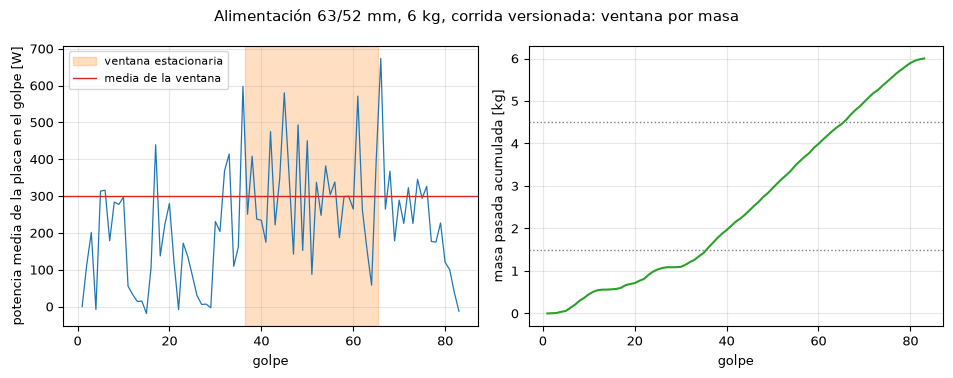

In [15]:
# Figura 2: la potencia de la placa en cada golpe de la corrida de tamaño completo con su ventana estacionaria, y
# la masa pasada con las marcas del 25 y el 75 por ciento
stroke = np.array(big["stroke"])
first, last = window.first_stroke - 0.5, window.last_stroke + 0.5
fig, axes = plt.subplots(1, 2, figsize=(9.6, 3.8))
axes[0].plot(stroke, big["plate_power_w"], "-", lw=0.9)
axes[0].axvspan(first, last, color="tab:orange", alpha=0.25, label="ventana estacionaria")
axes[0].axhline(power["mean"], color="tab:red", lw=1, label="media de la ventana")
axes[0].set_xlabel("golpe")
axes[0].set_ylabel("potencia media de la placa en el golpe [W]")
axes[0].legend(fontsize=8)
axes[1].plot(stroke, big["passed_kg"], "-", color="tab:green")
axes[1].axhline(0.25 * big["passed_kg"][-1], color="gray", ls=":", lw=1)
axes[1].axhline(0.75 * big["passed_kg"][-1], color="gray", ls=":", lw=1)
axes[1].set_xlabel("golpe")
axes[1].set_ylabel("masa pasada acumulada [kg]")
fig.suptitle("Alimentación 63/52 mm, 6 kg, corrida versionada: ventana por masa")
fig.tight_layout()
plt.show()

Lectura del paso 8b y de la figura 2. La ventana tiene los golpes 37 a 65, 29 golpes. La potencia media de la placa es 300,9 W con una desviación estándar de 133,9 W de golpe a golpe, una autocorrelación de rezago 1 de -0,301 (sin crédito, así que se usan los 29 golpes) y un error estándar de 24,9 W; la tendencia de -1,45 W por golpe tiene un error de 3,01, así que la potencia es estacionaria en la ventana. El caudal de la ventana es 2167 kg/h con un error estándar de 50 kg/h, y la energía específica 500 J/kg. La figura muestra lo que excluye la ventana: una rampa de unos 36 golpes en que se llena el lecho, y el vaciado tras el golpe 65; y muestra cuán ruidoso es un golpe junto a la media, cuyo error es cerca de un quinto de la dispersión de golpe a golpe. No muestra la dispersión entre semillas, que no se midió: el error estándar es el de una realización.

La celda imprime los números que usaron los pasos, las cotas del reemplazo y el control de corrida. Qué controla cada uno, y quién lo fija:

| Parámetro | Qué controla | Quién lo fija |
|---|---|---|
| $E_\infty$, $d_0$ | la energía de fractura mediana y su alza hacia los tamaños pequeños | el producto, con `paper_ore`, desde la Fig. 6b del artículo |
| $\phi$ | cuán rápido sube la resistencia por unidad de masa al achicarse las esferas | supuesto: el valor del gneis de Tavares (2022) |
| $\sigma^2$ | el ancho de la ley lognormal de energías de fractura | valor de los datos con tope en 1,2, el extremo superior del rango de la literatura |
| $\gamma$ | cuán rápido los eventos bajo el umbral debilitan una esfera | supuesto: 3,5, a mitad de 3 a 4 del artículo |
| $A$, $b'$ | el mayor $t_{10}$ de un evento y cuán rápido se alcanza | supuesto: los valores del gneis de Tavares (2022) |
| esfera mínima (4 mm) | dónde la progenie pasa a ser finos y el paso de tiempo | el producto; la razón entre la mayor y la menor no puede exceder 20 |
| `max_injection_fraction`, `max_relax_overlap`, `mass_tolerance` | las cotas del reemplazo | los valores por defecto del paquete, sin cambio |
| límite de traslape | la detención de una corrida | la escalera 0,3 y luego 0,5, fijada antes de toda corrida |
| casillas | el tope de partículas | 1500, 1500 y 3000 esferas para las tres alimentaciones |
| golpes de detención, límite de golpes, semilla, backend | las reglas de término y la reproducibilidad de la corrida | 40, 400, 1 y la ruta de CPU compilada |

In [16]:
# Los parámetros: los números de la roca, las cotas del reemplazo y el control de corrida que fija el producto
description = ore.describe()
keys = ("e_inf_j_kg", "d0_m", "phi", "variance", "emax_ratio", "gamma", "a_max_percent", "b_prime", "min_diameter_m")
ore_numbers = {k: description[k] for k in keys}
print("roca:", {k: (round(float(v), 5) if v is not None else v) for k, v in ore_numbers.items()})
print("cotas del reemplazo:", BreakageBounds().__dict__)
control = {"overlap_ladder": P.OVERLAP_LADDER, "stall_strokes": P.STALL_STROKES, "max_strokes": P.MAX_STROKES}
control.update(slots=[pt.capacity for pt in P.POINTS], seed=P.SEED, backend=P.BACKEND)
print("control de corrida del producto:", control)

roca: {'e_inf_j_kg': 13.83677, 'd0_m': 0.05502, 'phi': 1.82, 'variance': 1.2, 'emax_ratio': None, 'gamma': 3.5, 'a_max_percent': 59.7, 'b_prime': 0.025, 'min_diameter_m': 0.004}
cotas del reemplazo: {'mass_tolerance': 1e-09, 'max_injection_fraction': 0.1, 'max_relax_overlap': 0.001, 'max_relax_iterations': 400, 'min_damage_energy_fraction': 0.001}
control de corrida del producto: {'overlap_ladder': (0.3, 0.5), 'stall_strokes': 40, 'max_strokes': 400, 'slots': [1500, 1500, 3000], 'seed': 1, 'backend': 'numba'}


Los valores impresos son los de la tabla: la roca de la derivación, las tres cotas en los valores por defecto del paquete de $10^{-9}$, 0,1 y $10^{-3}$, y el control del producto con la escalera 0,3 y luego 0,5, 40 golpes de detención, un límite de 400 golpes, 1500, 1500 y 3000 casillas, semilla 1 y el backend numba. Ninguno de los tres grupos supuestos se ajustó para alcanzar un resultado: el registro del paquete declara que ninguna propiedad de la roca se fijó a partir del resultado de una corrida del chancador.

Dos resultados de los pasos se comprueban frente a valores que no vienen de la ruta de código del paquete. Primero, la ley de contacto: dos esferas de roca de 10 mm con restitución 1 y sin fricción chocan de frente a 2 m/s de velocidad relativa, y el máximo de su traslape, seguido paso a paso, se compara con la forma cerrada de la teoría de impacto de Hertz (Johnson, 1985),

$$\delta_{\max} = \left(\frac{15\,m^{*}\,v^{2}}{16\,E^{*}\sqrt{R^{*}}}\right)^{2/5},$$

con $m^{*}$ la masa reducida y $v$ la velocidad de aproximación, y la velocidad de rebote debe igualar la de aproximación. Segundo, el mapeo de la fuerza mediana a energía del paso 2, calculado de nuevo a mano para la clase 31,5/26,5 mm.

In [17]:
# Validación 1: una colisión frontal elástica de dos esferas de roca, su traslape máximo frente a la forma cerrada
# de Hertz
elastic = ContactTable.build([ore_mat], default=PairParams(restitution=1.0, friction=0.0))
at_rest = [[0.0, 0.0, 0.0], [0.0100001, 0.0, 0.0]]
pair = ParticleState.from_arrays(at_rest, [0.005, 0.005], elastic, vel=[[1.0, 0, 0], [-1.0, 0, 0]])
collision = Simulation(pair, elastic, dt=stable_time_step(pair, elastic, 0.02), gravity=(0.0, 0.0, 0.0))
peak = 0.0
for _ in range(900):
    collision.run(1)
    state = collision.state()
    peak = max(peak, 0.01 - (state.pos[1, 0] - state.pos[0, 0]))
m_star = 0.5 * 2700.0 * 4.0 / 3.0 * math.pi * 0.005**3
closed_form = (15.0 * m_star * 2.0**2 / (16.0 * e_star * math.sqrt(r_star))) ** 0.4
after = collision.state()
print(f"traslape máximo, paquete {peak * 1e6:.2f} um,",
      f"forma cerrada de Hertz {closed_form * 1e6:.2f} um,",
      f"diferencia {100 * (peak - closed_form) / closed_form:+.2f} %")
print(f"razón de velocidades de rebote con restitución 1: {(after.vel[1, 0] - after.vel[0, 0]) / 2.0:.4f}")

traslape máximo, paquete 173.70 um, forma cerrada de Hertz 173.69 um, diferencia +0.00 %
razón de velocidades de rebote con restitución 1: 1.0000


El traslape máximo simulado es 173,70 micrómetros frente a 173,69 de la forma cerrada, una diferencia de +0,00 por ciento, y la razón de rebote es 1,0000: la ley de contacto integra el problema de Hertz como lo enuncia la teoría. Es una comprobación del contacto, no de todo el método; no dice nada de la fractura.

In [18]:
# Validación 2: la energía que absorbe una esfera con su fuerza de ruptura mediana, a mano frente al mapeo del paquete
force_n, d_m = 1965.6, case.SIZE_CLASS_MEAN_M["31.5/26.5"]
steel = case.STEEL_MATERIAL
e_eff = effective_modulus(ore_mat, steel)
depth = (3.0 * force_n / (4.0 * e_eff * math.sqrt(0.5 * d_m))) ** (2.0 / 3.0)
hand = 2.0 * energy_share(ore_mat, steel) * 0.4 * force_n * depth
print(f"traslape de cada contacto {depth * 1e3:.3f} mm,",
      f"energía a mano {hand:.4f} J, paquete {case.energy_at_force(force_n, d_m):.4f} J")
per_mass = hand / (2700.0 * math.pi / 6.0 * d_m**3)
print(f"por unidad de masa: {per_mass:.2f} J/kg,",
      f"E50 de la derivación {derivation['e50_j_kg']['31.5/26.5']:.2f} J/kg")

traslape de cada contacto 1.294 mm, energía a mano 2.0073 J, paquete 2.0073 J
por unidad de masa: 58.22 J/kg, E50 de la derivación 58.22 J/kg


A mano, una esfera de la clase 31,5/26,5 mm apretada hasta su fuerza mediana de 1965,6 N se traslapa 1,294 mm en cada contacto y absorbe 2,0073 J, los mismos 2,0073 J del paquete, y 58,22 J/kg por unidad de masa, el E50 que imprimió la derivación para esa clase. El mapeo del paso 2 es entonces la aritmética que enuncia.

El método se quiebra donde el traslape, el artificio que representa la deformación elástica, deja de ser pequeño. La escalera del producto detiene una corrida en 0,3 del radio menor y, si eso ocurre, prueba una vez con 0,5. La primera prueba es en vivo: lotes de 0,25, 0,5 y 1 kg de la alimentación 16/13,2 mm, la más fina y rápida, en el primer peldaño. La corrida de 1 kg es la del paso 7. La segunda es el registro versionado de las corridas de tamaño completo, cada intento de las tres alimentaciones. Las celdas corren los dos lotes nuevos e imprimen el barrido.

In [19]:
# Dónde se quiebra: lotes de 0,25 y 0,5 kg de la misma alimentación con el mismo límite, junto a la corrida de 1
# kg de arriba
sweep = {1.0: run}
for batch in (0.25, 0.5):
    with contextlib.redirect_stdout(io.StringIO()):
        sweep[batch] = case.run_attempt(ore, batch, 6.0, 1, 1200, 0.3, "numba", 14, 900.0, 40, feed_class="16/13.2")
print("lote [kg]  estado           golpes  detenida en el golpe  mayor traslape  retenidas al final")
for batch in sorted(sweep):
    r = sweep[batch]
    print(f"{batch:9.2f}  {r['status']:15s} {r['strokes']:7d} {str(r['stopped_during_stroke']):>18s}",
          f"{r['max_overlap_reached']:16.3f} {r['series'][-1]['n_hold']:16d}")

lote [kg]  estado           golpes  detenida en el golpe  mayor traslape  retenidas al final
     0.25  complete              5               None            0.265                0
     0.50  overlap_error         3                  4            0.300               82
     1.00  complete             10               None            0.283                0


El barrido no muestra un alza suave del traslape con la masa retenida. El lote de 0,25 kg se completa en 5 golpes con un mayor traslape de 0,265, el de 0,5 kg se detiene en el golpe 4 con 0,300 y 82 esferas retenidas, y el de 1 kg se completa en 10 golpes con 0.283. En este rango el mayor traslape de un golpe está entre 0,26 y 0,30 sea cual sea el lote, y lo que cambia es si uno de los golpes cruza el límite: un valor extremo de una serie de golpes, que una corrida más larga tiene más oportunidades de producir. Las corridas versionadas de las tres alimentaciones son la prueba a tamaño completo de esa lectura.

In [20]:
# Las corridas de tamaño completo del documento versionado: cada intento de las tres alimentaciones, en cada
# peldaño de la escalera de traslape
print("alim. [mm]    límite  estado         golpes  detenida en  mayor traslape  esferas retenidas")
for pt in doc["points"]:
    for a in pt["simulation"]["attempts"]:
        print(f"{pt['feed_class']:>10s} {a['max_overlap_fraction']:8.1f}  {a['status']:14s} {a['strokes']:6d}",
              f"{str(a['stopped_during_stroke']):>11s} {a['max_overlap_reached']:15.3f} {a['held_spheres']:13d}")
reference = settings["overlap_reference"]
for fc in ("63/52", "16/13.2"):
    series_doc = final[fc]["series"]["max_overlap"]
    above = sum(1 for v in series_doc if v > reference)
    print(f"{fc}: {above} de {len(series_doc)} golpes del intento aceptado sobre {reference};",
          f"rango {min(series_doc):.3f} a {max(series_doc):.3f}")

alim. [mm]    límite  estado         golpes  detenida en  mayor traslape  esferas retenidas
     63/52      0.3  overlap_error       5           6           0.300           117
     63/52      0.5  complete           83        None           0.420             0
 31.5/26.5      0.3  overlap_error       2           3           0.301           264
 31.5/26.5      0.5  overlap_error       5           6           0.547           327
   16/13.2      0.3  overlap_error       9          10           0.301          1138
   16/13.2      0.5  complete           54        None           0.486             0
63/52: 33 de 83 golpes del intento aceptado sobre 0.3; rango 0.008 a 0.420
16/13.2: 23 de 54 golpes del intento aceptado sobre 0.3; rango 0.017 a 0.486


En el primer peldaño, 0,3, las tres corridas de tamaño completo se detienen: la alimentación 63/52 mm en el golpe 6 con 117 esferas retenidas, la 31,5/26,5 mm en el golpe 3 con 264 y la 16/13,2 mm en el golpe 10 con 1138. Con 0,5, la corrida 63/52 mm se completa en 83 golpes con un mayor traslape de 0,420, y la 16/13,2 mm en 54 golpes con 0.486. La corrida 31,5/26,5 mm se detiene otra vez, en el golpe 6, con 0,547 y 327 esferas retenidas, así que el documento no registra ninguna corrida completa para esa alimentación y sus veredictos son no comparados. En las dos corridas completas el intento aceptado pasa buena parte de su vida sobre el límite que detuvo su primer intento: 33 de los 83 golpes de la alimentación gruesa y 23 de los 54 golpes de la fina superan 0.3. El límite de 0,5 no hace válido el contacto; deja continuar la corrida donde la ley de contacto ya está lejos de las deformaciones pequeñas que supone. La figura 3 dibuja los golpes de los lotes en vivo y de la corrida de tamaño completo de la alimentación fina frente a ambos límites.

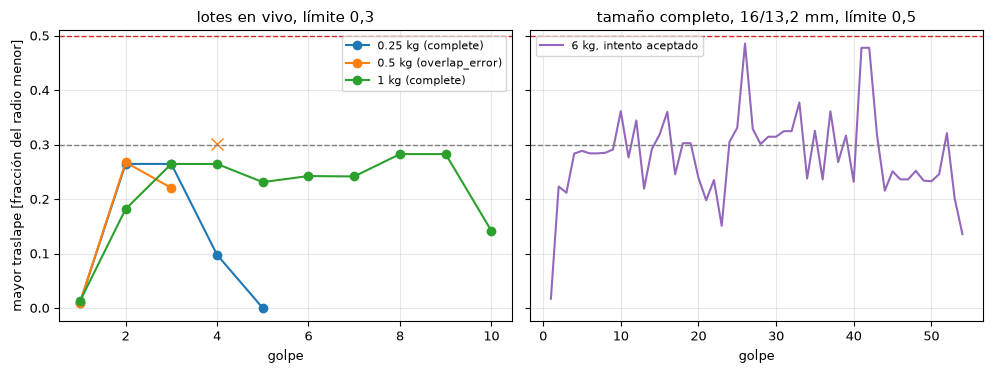

In [21]:
# Figura 3: el mayor traslape de cada golpe, en los lotes en vivo y en la corrida de tamaño completo de la misma
# alimentación, frente a los dos límites
fig, axes = plt.subplots(1, 2, figsize=(10.0, 3.8), sharey=True)
for batch in sorted(sweep):
    r = sweep[batch]
    strokes_r = [row["stroke"] for row in r["series"]]
    overlaps = [row["max_overlap"] for row in r["series"]]
    line = axes[0].plot(strokes_r, overlaps, "o-", label=f"{batch:g} kg ({r['status']})")
    if r["stopped_during_stroke"]:
        axes[0].plot(r["stopped_during_stroke"], r["max_overlap_reached"], "x", ms=9, color=line[0].get_color())
axes[0].set_title("lotes en vivo, límite 0,3")
full = final["16/13.2"]["series"]
axes[1].plot(full["stroke"], full["max_overlap"], "-", color="tab:purple", label="6 kg, intento aceptado")
for ax in axes:
    ax.axhline(0.3, color="gray", ls="--", lw=1)
    ax.axhline(0.5, color="tab:red", ls="--", lw=1)
    ax.set_xlabel("golpe")
    ax.legend(fontsize=8)
axes[0].set_ylabel("mayor traslape [fracción del radio menor]")
axes[1].set_title("tamaño completo, 16/13,2 mm, límite 0,5")
fig.tight_layout()
plt.show()

Lectura de la figura 3. A la izquierda los tres lotes en vivo se mantienen bajo 0,3 salvo el de 0,5 kg, que lo toca y se detiene, y sus curvas no tienen una tendencia común con la masa. A la derecha la corrida de tamaño completo tampoco deriva hacia arriba: su mayor traslape oscila de golpe a golpe en todo el rango impreso arriba, cruzando la línea de 0,3 muchas veces antes de que termine el lote. La figura no muestra qué causa los traslapes grandes, un lecho atascado o un evento local, porque el registro del paquete no los separa; el README y el registro de validación del paquete (Santibanez-Leal, 2026) listan la rigidez del contacto, seis veces más blanda que la que implica la calibración del propio artículo, entre siete causas candidatas que no se probaron.

Se necesitan tres cosas: la máquina, la roca y la alimentación. La máquina se construye con `crushdem.machines.jaw` con la abertura de alimentación, el lado cerrado, la carrera, el ancho de placas, el ángulo de agarre y la frecuencia, o, para el chancador del artículo, con `jaw_barrios2020`, cuyas dimensiones llevan su fuente en `machine.provenance`; la tabla de contactos da los materiales y la restitución y fricción de cada par. La roca es un `Ore` con los ocho parámetros de la tabla de arriba, que para tu roca salen de ensayos de compresión de una partícula: la fuerza de ruptura mediana de al menos dos clases de tamaño, mapeada a energía con `case.energy_at_force` y ajustada con `case.fixed_phi_fit`, exactamente como lo hace `paper_ore`. La alimentación es una lista de clases de tamaño (`SizeClass`) con una masa de lote, y `machine.feed` sortea las esferas con una semilla. `case.build` los ensambla, `case.run_attempt` corre los golpes y `comparison.window_statistics` lee el resultado.

La primera celda toma las tres medianas de clase del artículo como si fueran tus ensayos e imprime las energías mapeadas y el desajuste del ajuste.

In [22]:
# Su propia roca: medianas de ensayos de una partícula a energías de fractura, luego un efecto de tamaño (las
# medianas de las clases del artículo hacen de sus ensayos)
my_forces = {"63/53": 4831.05, "31.5/26.5": 1965.6, "16.0/13.2": 1701.95}
sizes_m = np.array([case.SIZE_CLASS_MEAN_M[k] for k in my_forces])
masses = 2700.0 * math.pi / 6.0 * sizes_m**3
energies = np.array([case.energy_at_force(f, d) for f, d in zip(my_forces.values(), sizes_m)]) / masses
e_inf, d0, residual = case.fixed_phi_fit(sizes_m, energies, ore.phi)
print(f"E50 mapeada [J/kg] {np.round(energies, 1)}, E_inf = {e_inf:.2f} J/kg, d0 = {d0 * 1e3:.2f} mm")
print("desajuste de cada clase en ln E50:", np.round(residual, 3))

E50 mapeada [J/kg] [ 26.6  58.2 451.1], E_inf = 13.84 J/kg, d0 = 55.02 mm
desajuste de cada clase en ln E50: [-0.     0.    -0.984]


La celda de la roca devuelve las energías mapeadas de las clases del artículo, 26,6, 58,2 y 451,1 J/kg, y el ajuste, 13,84 J/kg y 55,02 mm, con un desajuste de -0,984 en la tercera clase: la comprobación que hay que hacer con tus propios ensayos es si ese residuo es pequeño en cada clase que dejaste en el ajuste, y qué hace la extrapolación a los tamaños que no ensayaste. La segunda celda corre un chancador distinto, un lado cerrado de 10 mm a 5 Hz, durante tres golpes de 0,25 kg, e imprime las tres cosas que hay que leer en toda salida: el estado, el residuo del balance de masa y el mayor traslape, y luego si la corrida tiene ventana.

In [23]:
# Su propio chancador: otro ajuste y otra frecuencia con el mismo constructor, y las tres cosas que hay que leer
# en su salida
with contextlib.redirect_stdout(io.StringIO()):
    mine = case.run_attempt(ore, 0.25, 5.0, 1, 800, 0.3, "numba", 3, 300.0, 40,
                            feed_class="16/13.2", closed_side_setting=0.010)
checks = comparison.window_statistics(mine["series"], 1.0 / 5.0)
print(f"estado {mine['status']}; residuo del balance de masa {mine['mass_balance_residual_kg']:.1e} kg;",
      f"mayor traslape {mine['max_overlap_reached']:.3f}")
print("ventana:", checks["window"], "|", checks.get("reason", "encontrada"))

estado complete; residuo del balance de masa 6.3e-17 kg; mayor traslape 0.146
ventana: None | the run has 3 strokes, fewer than the 6 a window needs: no window


La celda del chancador se completa con un residuo del balance de masa de 6,3e-17 kg, que es redondeo, y un mayor traslape de 0,146, bien dentro de 0,3. Su ventana está ausente, con la razón que da el paquete: la corrida tiene 3 golpes, menos de los 6 que necesita una ventana. Tres lecturas deciden entonces si un resultado es un resultado: el balance cierra hasta el redondeo, el traslape queda bajo el límite en los golpes sobre los que se toma el promedio, y la ventana existe y es lo bastante larga para que su error y su tendencia estén definidos.

## Resultados

**Respuesta:** La simulación decide que una esfera se rompe cuando la energía específica de su evento, tomada del trabajo de sus contactos, alcanza una energía de fractura sorteada una vez de una ley lognormal cuya mediana es 168,6 J/kg a 14,6 mm; los eventos bajo ella debilitan la esfera por $E' = E(1-D)$, de modo que una esfera golpeada con eventos de 50,6 J/kg se rompe en el octavo. La fractura se reemplaza por piezas cuyos tamaños salen de $t_{10}$ (5,354 por ciento para una esfera de 57,5 mm con 100 J/kg, 0,879 para una de 14,6 mm), conservando la masa hasta 5,1e-16 del padre e inyectando a lo más 4,93e-03 de la energía absorbida. Las dos piezas de esta cadena que se pueden comprobar de forma independiente coinciden: el traslape máximo del contacto con 173,70 frente a 173,69 micrómetros, y el mapeo de energía con 2,0073 J.

El método deja de funcionar en este chancador donde el traslape pasa el límite que hace significativo el contacto. Con 0,3 las tres corridas versionadas de tamaño completo se detienen, en los golpes 6, 3 y 10; con 0,5 la alimentación gruesa y la fina se completan, en 83 y 54 golpes, con 33 y 23 de sus golpes sobre 0,3, y la alimentación intermedia se detiene otra vez con 0,547 en el golpe 6 con 327 esferas retenidas. De tres alimentaciones, dos dan una ventana, con una potencia media de la placa de 300,9 W y un error estándar de 24,9 W para la gruesa, y una no da nada que comparar.

## Resumen

- Una esfera se rompe cuando la energía de su evento alcanza su energía de fractura, sorteada una vez de una ley lognormal cuya mediana baja con el tamaño y cuyo ancho fija $\sigma^2$; los eventos bajo ella suman daño por $E' = E(1-D)$.
- La progenie sale de $t_{10} = A[1 - \exp(-b'\,e E_k/E_{50})]$ y de la función beta incompleta, se sortea como esferas, conserva la masa y está acotada en energía inyectada.
- Una corrida se detiene cuando su mayor traslape pasa una fracción del radio menor, y la escalera del producto prueba 0,3 y luego 0,5: con 0,3 las tres corridas versionadas de tamaño completo se detienen, con 0,5 dos de las tres alimentaciones se completan y la intermedia no.
- La ventana de un lote se fija por masa, su error estándar toma la autocorrelación de rezago 1 de los golpes, y una ventana de tres golpes no puede declarar una tendencia.
- Tu propio chancador necesita una máquina, una roca de ensayos de una partícula y una alimentación, y tres lecturas de la salida: el balance de masa, el traslape y la ventana.
- El notebook 03 enfrenta la simulación de partículas a la medición y al balance poblacional con un modelo de capacidad de mandíbulas.

## Referencias

- Barrios, G. K., Jiménez-Herrera, N., Fuentes-Torres, S. N., Tavares, L. M. (2020). DEM simulation of laboratory-scale jaw crushing of a gold-bearing ore using a particle replacement model. Minerals 10(8), 717. https://doi.org/10.3390/min10080717
- Bayley, G. V., Hammersley, J. M. (1946). The "effective" number of independent observations in an autocorrelated time series. Supplement to the Journal of the Royal Statistical Society 8(2), 184-197. https://doi.org/10.2307/2983560
- Cleary, P. W., Sinnott, M. D. (2015). Simulation of particle flows and breakage in crushers using DEM: Part 1, Compression crushers. Minerals Engineering 74, 178-197. https://doi.org/10.1016/j.mineng.2014.10.021
- Johnson, K. L. (1985). Contact mechanics. Cambridge University Press. https://doi.org/10.1017/CBO9781139171731
- Santibanez-Leal, F. (2026). crushdem 0.6.0, package page and README, with the candidate causes of the jaw result. https://pypi.org/project/crushdem/
- Tavares, L. M. (2022). Review and further validation of a practical single-particle breakage model. KONA Powder and Particle Journal 39, 62-83. https://doi.org/10.14356/kona.2022012
- Tsuji, Y., Tanaka, T., Ishida, T. (1992). Lagrangian numerical simulation of plug flow of cohesionless particles in a horizontal pipe. Powder Technology 71(3), 239-250. https://doi.org/10.1016/0032-5910(92)88030-L
- El paso de tiempo de Rayleigh, según la documentación de fix check/timestep/gran, https://www.cfdem.com/media/DEM/docu/fix_check_timestep_gran.html